[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/02_words_to_vectors.ipynb)

# 02 · Words to Vectors

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

Attention works on **vectors**, not words. So before we can let one word "look at" another, we need to turn text into numbers whose geometry means something. This notebook goes from raw text to tokens to embeddings, and learns a small set of meaningful word vectors from scratch — no downloads needed.

**Learning objectives.** By the end of this notebook you will be able to:

- explain **character, word and subword (BPE)** tokenization and implement a tiny BPE
- see why **one-hot** vectors carry no notion of similarity
- understand an **embedding** as a trainable lookup table
- learn word vectors from **co-occurrence** counts and measure **cosine similarity**
- visualise an embedding space with **PCA**

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Tokenization: cutting text into pieces

A neural network cannot read letters; it reads **numbers**. Step one is to split text into **tokens** and give each token an integer id. There are three common granularities:

| level | example tokens for *"unhappiness"* | vocabulary size | sequence length |
|-------|-----------------------------------|-----------------|-----------------|
| character | `u n h a p p i n e s s` | tiny (~100) | long |
| word | `unhappiness` | huge (every word form) | short |
| **subword** (BPE, WordPiece) | `un happi ness` | medium (~30–100k) | medium |

Modern models use **subwords**. Let's try the two simple ones on our toy corpus first.

In [2]:
sentence = "The king and the queen live in the castle"
words = au.tokenize(sentence)
chars = list(sentence.lower().replace(" ", "_"))
print("word tokens:", words, f"({len(words)} tokens)")
print("char tokens:", chars, f"({len(chars)} tokens)")

corpus_tokens = [au.tokenize(s) for s in au.TOY_CORPUS]
vocab = sorted({w for s in corpus_tokens for w in s})
w2i = {w: i for i, w in enumerate(vocab)}
print(f"\nToy corpus: {len(au.TOY_CORPUS)} sentences, {sum(map(len, corpus_tokens))} tokens, vocabulary of {len(vocab)} words")
print("ids:", [w2i[w] for w in words])

word tokens: ['the', 'king', 'and', 'the', 'queen', 'live', 'in', 'the', 'castle'] (9 tokens)
char tokens: ['t', 'h', 'e', '_', 'k', 'i', 'n', 'g', '_', 'a', 'n', 'd', '_', 't', 'h', 'e', '_', 'q', 'u', 'e', 'e', 'n', '_', 'l', 'i', 'v', 'e', '_', 'i', 'n', '_', 't', 'h', 'e', '_', 'c', 'a', 's', 't', 'l', 'e'] (41 tokens)

Toy corpus: 45 sentences, 262 tokens, vocabulary of 90 words
ids: [80, 48, 2, 80, 66, 50, 44, 80, 13]


### A tiny Byte-Pair Encoding (BPE)

BPE starts from characters and repeatedly **merges the most frequent adjacent pair** into a new token. After enough merges, frequent words become single tokens while rare words stay split into reusable pieces. Here is the whole algorithm in a dozen lines, learning 30 merges from our corpus.

In [3]:
from collections import Counter

def learn_bpe(words, n_merges):
    # each word is a tuple of symbols; '</w>' marks the end of a word
    vocab_counts = Counter(tuple(w) + ("</w>",) for s in words for w in s)
    merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for word, c in vocab_counts.items():
            for a, b in zip(word, word[1:]):
                pairs[(a, b)] += c
        if not pairs:
            break
        best = max(pairs, key=pairs.get)
        merges.append(best)
        new = Counter()
        for word, c in vocab_counts.items():
            out, i = [], 0
            while i < len(word):
                if i < len(word) - 1 and (word[i], word[i + 1]) == best:
                    out.append(word[i] + word[i + 1]); i += 2
                else:
                    out.append(word[i]); i += 1
            new[tuple(out)] += c
        vocab_counts = new
    return merges

def apply_bpe(word, merges):
    sym = list(word) + ["</w>"]
    for a, b in merges:
        i, out = 0, []
        while i < len(sym):
            if i < len(sym) - 1 and sym[i] == a and sym[i + 1] == b:
                out.append(a + b); i += 2
            else:
                out.append(sym[i]); i += 1
        sym = out
    return sym

merges = learn_bpe(corpus_tokens, 30)
print("first 10 merges:", merges[:10])
for w in ["the", "queen", "kingdom", "walking", "unhappiness"]:
    print(f"{w:12s} ->", apply_bpe(w, merges))

first 10 merges: [('e', '</w>'), ('t', 'h'), ('th', 'e</w>'), ('s', '</w>'), ('n', '</w>'), ('a', '</w>'), ('a', 'n'), ('i', 'n'), ('i', 's</w>'), ('i', 'n</w>')]
the          -> ['the</w>']
queen        -> ['q', 'u', 'ee', 'n</w>']
kingdom      -> ['k', 'in', 'g', 'do', 'm', '</w>']
walking      -> ['w', 'al', 'k', 'ing</w>']
unhappiness  -> ['u', 'n', 'h', 'a', 'p', 'p', 'in', 'e', 's', 's</w>']


Frequent words (*the*) collapse into one token; unseen words (*unhappiness*) fall back to smaller pieces instead of becoming an unknown token. For the rest of the course we use simple **word** tokens, because they are easier to read in a heatmap — the attention maths is identical for any token type.

## 2. One-hot vectors carry no meaning

The simplest numeric representation gives every word its own axis: a **one-hot** vector with a single 1. The problem: every pair of different words is exactly as far apart as every other pair.

In [4]:
def one_hot(word):
    v = np.zeros(len(vocab)); v[w2i[word]] = 1.0
    return v

for a, b in [("king", "queen"), ("king", "banana"), ("dog", "cat")]:
    print(f"cos({a}, {b}) = {au.cosine(one_hot(a), one_hot(b)):.2f}")

cos(king, queen) = 0.00
cos(king, banana) = 0.00
cos(dog, cat) = 0.00


*king* is no closer to *queen* than to *banana*. We want **dense** vectors where similar words point in similar directions.

## 3. An embedding is just a lookup table

An **embedding matrix** $E$ has one row per vocabulary word and $d$ columns. Looking up a word is the same as multiplying its one-hot vector by $E$ — that is why in PyTorch it is called `nn.Embedding` and is trained like any other weight matrix.

In [5]:
d = 4
E_random = np.random.randn(len(vocab), d)
print("row lookup     :", E_random[w2i["king"]])
print("one-hot @ E    :", one_hot("king") @ E_random)

row lookup     : [-0.039 -1.168  0.523 -0.172]
one-hot @ E    : [-0.039 -1.168  0.523 -0.172]


## 4. Learning meaningful vectors from co-occurrence

*"You shall know a word by the company it keeps"* (J. R. Firth, 1957). Words that appear in similar contexts have similar meanings. The classic count-based recipe, a close cousin of GloVe:

1. **Count** how often each word appears within a few positions of each other word.
2. Convert counts to **PPMI** (positive pointwise mutual information): *does this pair co-occur more than chance?*
3. Compress the big PPMI matrix with **SVD** into dense $d$-dimensional vectors.

`au.cooccurrence_embeddings` does exactly that (read it in `attn_utils.py`, it is ~20 lines). No downloads: the vectors are learned from our 45 toy sentences in milliseconds.

In [6]:
vocab, w2i, E = au.cooccurrence_embeddings(dim=16)
print("embedding matrix:", E.shape, "(words × dimensions)")

pairs = [("king", "queen"), ("man", "woman"), ("dog", "cat"), ("coffee", "tea"),
         ("paris", "rome"), ("car", "bus"), ("apple", "banana"),
         ("king", "apple"), ("dog", "coffee"), ("queen", "road")]
for a, b in pairs:
    print(f"cos({a:6s}, {b:7s}) = {au.cosine(E[w2i[a]], E[w2i[b]]):+.3f}")

embedding matrix: (90, 16) (words × dimensions)
cos(king  , queen  ) = +0.969
cos(man   , woman  ) = +0.874
cos(dog   , cat    ) = +0.976
cos(coffee, tea    ) = +0.983
cos(paris , rome   ) = +1.000
cos(car   , bus    ) = +0.758
cos(apple , banana ) = +0.537
cos(king  , apple  ) = -0.005
cos(dog   , coffee ) = +0.088
cos(queen , road   ) = +0.089


Now related words have high cosine similarity and unrelated words are near zero — learned purely from which words keep each other company. Let's list nearest neighbours.

In [7]:
En = E / np.linalg.norm(E, axis=1, keepdims=True)
def neighbours(word, k=4):
    sims = En @ En[w2i[word]]
    order = np.argsort(-sims)
    return [(vocab[i], round(float(sims[i]), 3)) for i in order if vocab[i] != word][:k]

for w in ["king", "dog", "coffee", "paris", "car", "apple"]:
    print(f"{w:7s} ->", neighbours(w))

king    -> [('queen', 0.969), ('kingdom', 0.949), ('rules', 0.926), ('of', 0.918)]
dog     -> [('cat', 0.976), ('mouse', 0.809), ('meat', 0.696), ('chases', 0.687)]
coffee  -> [('tea', 0.983), ('banana', 0.412), ('drinks', 0.374), ('he', 0.36)]
paris   -> [('madrid', 1.0), ('rome', 1.0), ('berlin', 1.0), ('father', 0.948)]
car     -> [('bus', 0.758), ('road', 0.754), ('bike', 0.724), ('walking', 0.713)]
apple   -> [('an', 0.954), ('day', 0.871), ('every', 0.855), ('banana', 0.537)]


### Seeing the space

16 dimensions cannot be drawn, so we project onto the 2 principal components with **PCA**. Groups of related words should form clusters.

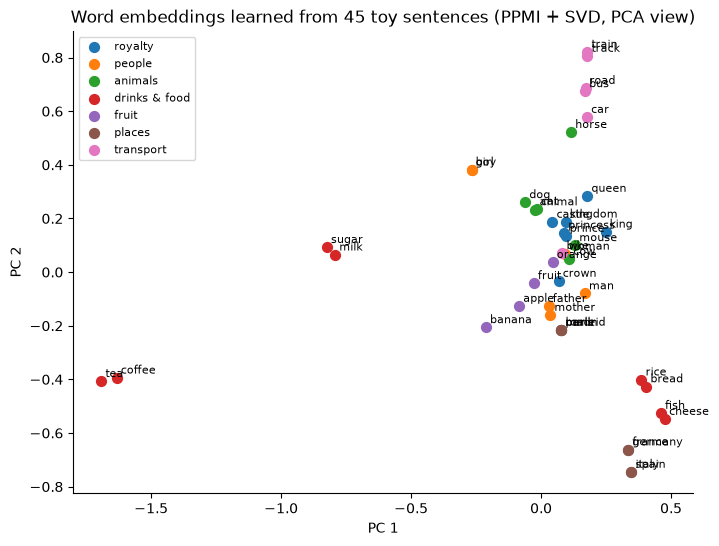

In [8]:
from sklearn.decomposition import PCA

groups = {
    "royalty": ["king", "queen", "prince", "princess", "crown", "castle", "kingdom"],
    "people": ["man", "woman", "boy", "girl", "father", "mother"],
    "animals": ["dog", "cat", "mouse", "horse", "cow", "animal"],
    "drinks & food": ["coffee", "tea", "milk", "sugar", "bread", "cheese", "rice", "fish"],
    "fruit": ["apple", "banana", "orange", "fruit"],
    "places": ["paris", "rome", "berlin", "madrid", "france", "italy", "germany", "spain"],
    "transport": ["car", "bus", "train", "bike", "road", "track"],
}
words_plot = [w for g in groups.values() for w in g]
XY = PCA(n_components=2, random_state=0).fit_transform(E[[w2i[w] for w in words_plot]])

fig, ax = plt.subplots(figsize=(8, 6))
i = 0
for (g, ws), col in zip(groups.items(), plt.cm.tab10.colors):
    pts = XY[i:i + len(ws)]; i += len(ws)
    ax.scatter(pts[:, 0], pts[:, 1], color=col, s=50, label=g)
    for (x_, y_), w in zip(pts, ws):
        ax.annotate(w, (x_, y_), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax.set_title("Word embeddings learned from 45 toy sentences (PPMI + SVD, PCA view)")
ax.legend(fontsize=8, loc="best")
au.save_fig(fig, "02_embedding_scatter.png")
plt.show()

Even from 45 sentences the space organises itself into themes. Real models learn the same kind of geometry from billions of tokens, in hundreds or thousands of dimensions.

## 5. Why this matters for attention

Attention is built on the **dot product** between vectors: a large dot product means "these two vectors point the same way", i.e. *related*. Cosine similarity is just a normalised dot product. So the moment words become vectors with meaningful geometry, a model can compute *how relevant word B is to word A* with a single multiplication. That is the whole trick of the next notebook.

## Key takeaways

- Text → **tokens** (characters, words or subwords) → integer ids → **vectors**.
- One-hot vectors are all orthogonal: no notion of similarity.
- An **embedding** is a trainable lookup table; good embeddings put related words close together.
- Similarity between vectors = **dot product / cosine** — the raw material of attention.

### ✏️ Exercise 1

Learn 80 BPE merges instead of 30 and tokenize `"kingdom"` and `"princess"` again. What changes?

<details>
<summary><b>Show solution</b></summary>

```python
merges80 = learn_bpe(corpus_tokens, 80)
for w in ["kingdom", "princess"]:
    print(w, apply_bpe(w, merges), "->", apply_bpe(w, merges80))
```

More merges → longer, more word-like tokens.

</details>

### ✏️ Exercise 2

The famous analogy *king − man + woman ≈ queen*. Compute the vector `E[king] - E[man] + E[woman]` and find its 3 nearest words (excluding the three inputs).

<details>
<summary><b>Show solution</b></summary>

```python
q = E[w2i["king"]] - E[w2i["man"]] + E[w2i["woman"]]
q = q / np.linalg.norm(q)
order = np.argsort(-(En @ q))
print([vocab[i] for i in order if vocab[i] not in ("king", "man", "woman")][:3])
```

With only 45 sentences the analogy is noisy — check whether *queen* makes the top 3 on your run. Large corpora make these analogies much cleaner.

</details>

### ✏️ Exercise 3

Rebuild the embeddings with `dim=4` and `dim=32`. How does `cos(king, queen)` change compared with `cos(king, apple)`?

<details>
<summary><b>Show solution</b></summary>

```python
for dim in (4, 16, 32):
    v, w, Ed = au.cooccurrence_embeddings(dim=dim)
    print(dim, round(au.cosine(Ed[w['king']], Ed[w['queen']]), 3), round(au.cosine(Ed[w['king']], Ed[w['apple']]), 3))
```



</details>